# Latent safety filter: reachability in a world model's latent space keeps a planner out of a hazard

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/safety/latent_safety_filter.ipynb)

The [Latent Safety Filter](https://arxiv.org/abs/2502.00935) ([code](https://github.com/CMU-IntentLab/latent-safety)) adds safety to any latent world model without touching it. A classifier on the frozen latents defines what failure looks like, a value function learned by Hamilton-Jacobi reachability *in imagination* tells from which latents failure can still be avoided, and a least-restrictive filter lets a task policy act until its next imagined latent leaves the safe set, when the value function's own safety policy takes over. Here a red hazard is drawn on PLDM's Two-Rooms floor: a goal-reaching planner that only sees goal images crosses it on its way, and the filter has to keep it out.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import time

import torch
from torch.utils.data import DataLoader, TensorDataset

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.envs.sdf import box, grid, paint, union
from torch_world.models import PLDM, PLDMEncoder
from torch_world.planning import CEM
from torch_world.safety import FailureMargin, SafetyFilter, SafetyValue, fit_safety_value
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## A hazard you can see
Two-Rooms with two red pools, one in each room on the way to the door. Entering a pool is a **failure**: it does not stop the point, so a policy that ignores it walks straight through. The pools are painted translucent, so the point stays visible inside one and failure shows in the pixels, as in the paper's settings; the labels come from the true position, as the paper labels its simulated data with privileged state.

4.2% of the frames are failures; 68% of the episodes enter a pool


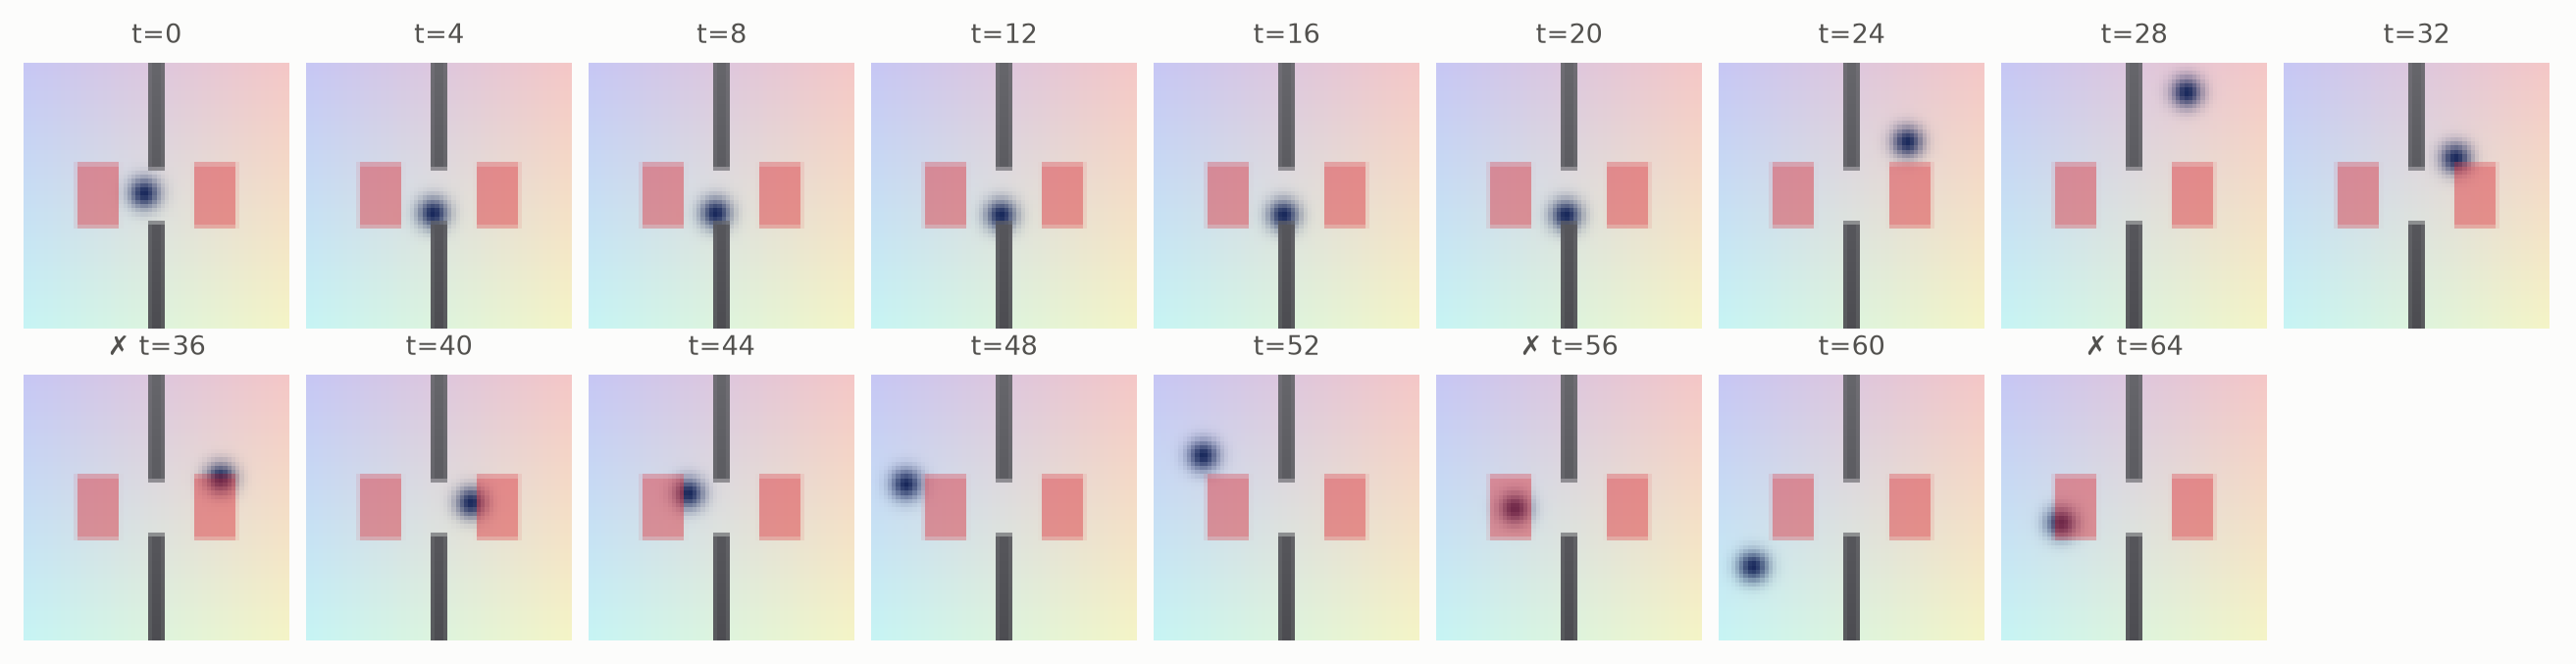

In [3]:
HAZARDS = [((0.28, 0.5), (0.08, 0.12)), ((0.72, 0.5), (0.08, 0.12))]  # centers and half sizes


class HazardRooms(TwoRooms):
    def hazard_sdf(self, x, y):
        return union(*(box(x, y, center, half) for center, half in HAZARDS))

    def failure(self, states):
        """Whether positions ``(..., 2)`` are inside a pool."""
        return self.hazard_sdf(states[..., 0], states[..., 1]) < 0

    def render(self, state=None):
        x, y = grid(self.size, self.state.device if state is None else state.device)
        return paint(super().render(state), self.hazard_sdf(x, y), (0.86, 0.16, 0.2), self.size, opacity=0.45)


def tasks(n, seed):
    """Starts and goals in opposite rooms, both at least 0.03 away from the pools."""
    pool = HazardRooms(batch_size=8 * n, device=device)
    start, goal = pool.tasks(generator=torch.Generator().manual_seed(seed))
    clear = lambda s: pool.hazard_sdf(s[:, 0], s[:, 1]) > 0.03
    keep = (clear(start) & clear(goal)).nonzero()[:n, 0]
    return start[keep], goal[keep]


env = HazardRooms(batch_size=1024, device=device)
data = env.collect(65, generator=torch.Generator().manual_seed(0))
data["failure"] = env.failure(data["states"])
print(f"{data['failure'].float().mean():.1%} of the frames are failures; {data['failure'].any(1).float().mean():.0%} of the episodes enter a pool")
plots.images(data["pixels"][3, ::4].cpu(), [("✗ " if f else "") + f"t={4 * t}" for t, f in enumerate(data["failure"][3, ::4].tolist())], ncols=9)

## World model
PLDM with the recipe of the [PLDM notebook](../action/pldm.ipynb): an IMPALA-style encoder to 128-d latents and a GRU predictor, trained reward-free on the random-action episodes cut into 17-frame windows. It never sees the failure labels. From here on it is frozen.

0.54M parameters


trained in 22.0 min


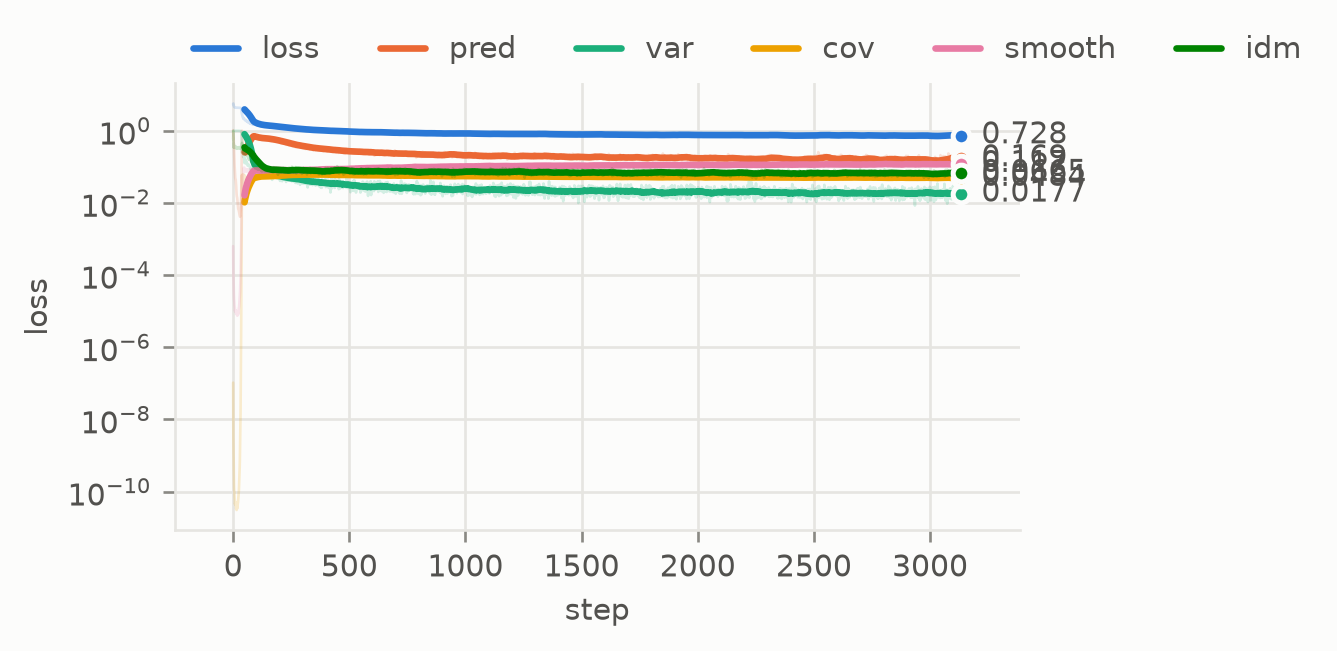

In [4]:
loader = DataLoader(TrajectoryDataset({k: data[k] for k in ("pixels", "actions")}, window=17), batch_size=128, shuffle=True, drop_last=True)
model = PLDM(PLDMEncoder(img_size=64, latent_dim=128), action_dim=2, latent_dim=128).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")
tic = time.time()
log = fit(model, loader, epochs=8, lr=1e-3, weight_decay=0)
print(f"trained in {(time.time() - tic) / 60:.1f} min")
model.requires_grad_(False)
plots.curves(log, smooth=50)

## Failure margin
Every frame is encoded once with the frozen encoder, and a 2-layer MLP learns the signed margin `l(z) = tanh(s(z))` with the paper's two hinges (`δ = 0.75`, the reference code's value), each averaged over its own class so the rare failures count as much as the safe frames. 900 episodes train it and 124 measure it.

held-out frames: failures caught 100.0%, false alarms on safe frames 1.0%


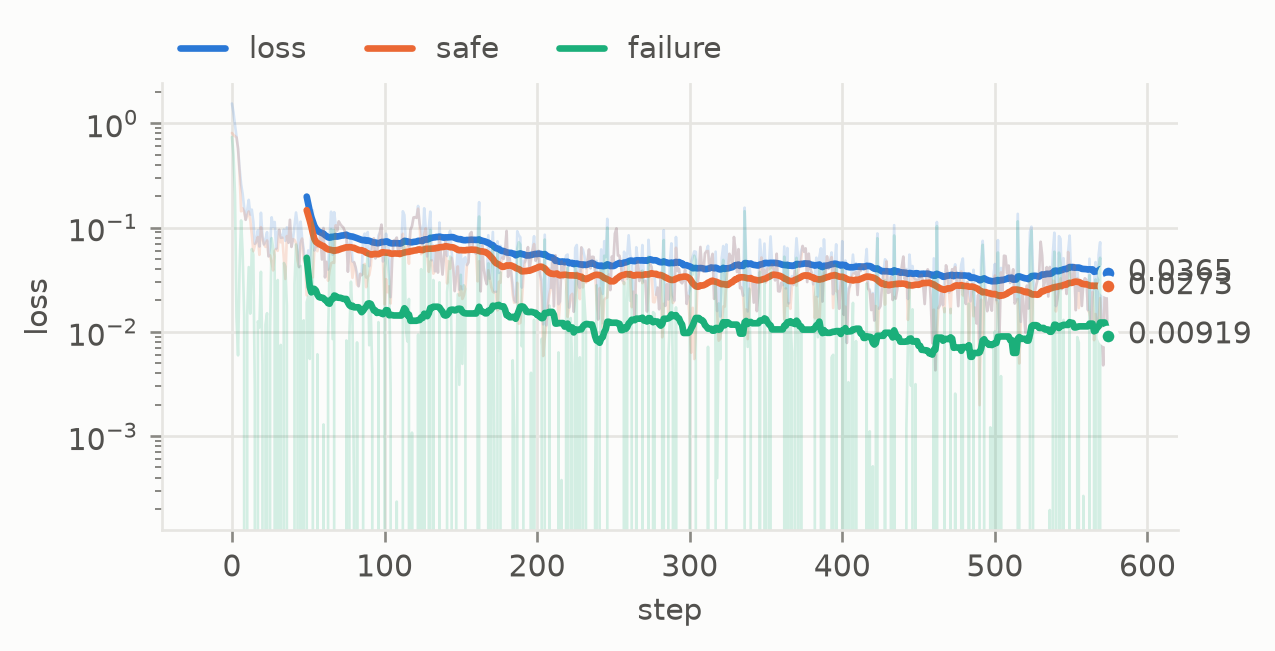

In [5]:
with torch.no_grad():
    latents = torch.cat([model.encode(p) for p in data["pixels"].split(64)])  # (1024, 65, 128)
labels = data["failure"]
margin = FailureMargin(128, hidden=(256, 256)).to(device)
margin_loader = DataLoader(TensorDataset(latents[:900].flatten(0, 1), labels[:900].flatten()), batch_size=512, shuffle=True)
margin_log = fit(margin, margin_loader, epochs=5, lr=1e-3, inputs=lambda b: b)
margin.requires_grad_(False)

with torch.no_grad():
    predicted = margin.margin(latents[900:]) < 0
truth = labels[900:]
print(f"held-out frames: failures caught {predicted[truth].float().mean():.1%}, false alarms on safe frames {predicted[~truth].float().mean():.1%}")
plots.curves(margin_log, smooth=50)

## Safety value by reachability in imagination
The value function is learned with the paper's DDPG: a critic `Q(z, a)` regresses the discounted avoid backup

`Q(z, a) ← (1 − γ) l(z) + γ min(l(z), Q'(z', π'(z')))`, with `z' = f(z, a)` imagined by the frozen PLDM,

and an actor `π(z)`, the safety policy, maximizes the critic; `Q'` and `π'` are Polyak-averaged targets. Imagined episodes start from encoded dataset frames and last 25 steps, as in the paper; exploration and the warm-up (random actions with γ = 0, fitting `Q` to `l`) follow the reference code, and so do γ = 0.9999, the learning rates (actor 1e-4, critic 1e-3), batch 512, the 40,000-transition buffer and one update per 8 imagined transitions. `V(z) = Q(z, π(z))`.

trained in 15.7 min


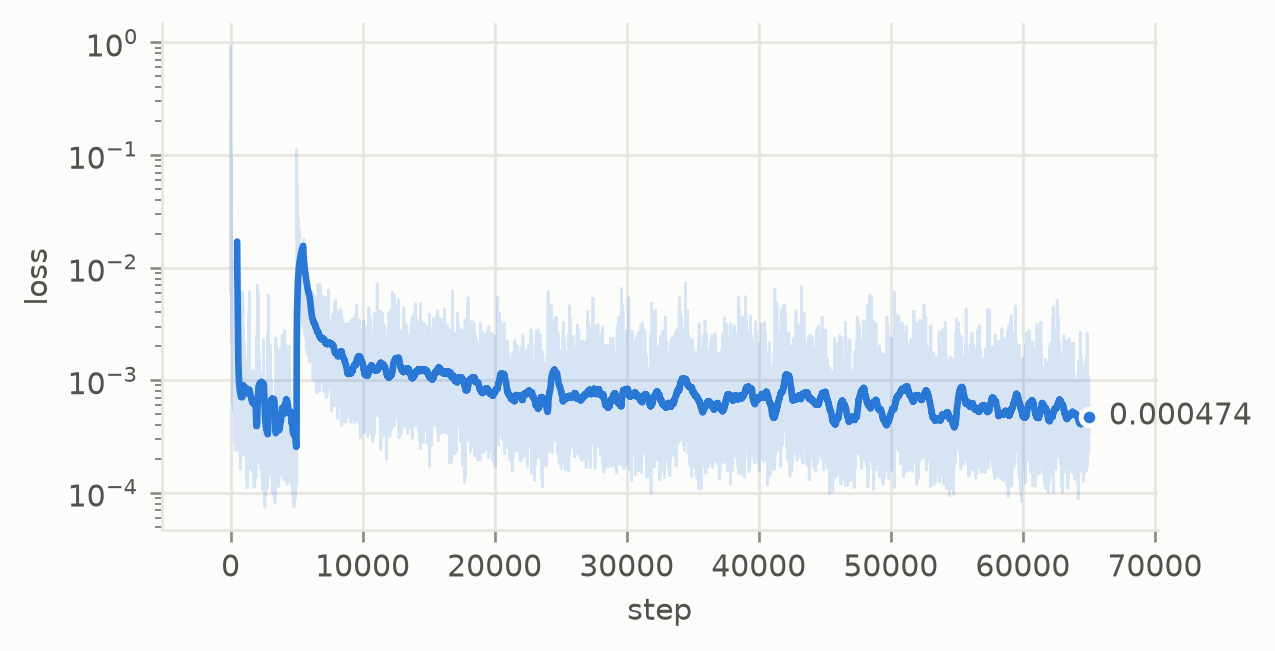

In [6]:
value = SafetyValue(128, action_dim=2, hidden=(512, 512, 512, 512), gamma=0.9999).to(device)
tic = time.time()
value_log = fit_safety_value(value, model, margin, latents.flatten(0, 1), iterations=60_000, warmup=5000, horizon=25, envs=8, generator=torch.Generator().manual_seed(0))
print(f"trained in {(time.time() - tic) / 60:.1f} min")
plots.curves({"critic": value_log["critic"]}, smooth=500)

### What the value function learned
`l(z)` and `V(z)` for frames rendered with the point at every position of a 64 × 64 grid (white: the wall, where the point cannot be). The black outlines are the true pools. Below zero (red) is unsafe. With these dynamics, velocity commands that can stop at once, nothing outside a pool is doomed, so the reachable unsafe set should hug the pools: `V` should look like `l`, a little more conservative.

failure margin l(z)  negative inside the pools 100%, outside 2.3%
safety value V(z)    negative inside the pools 100%, outside 2.3%


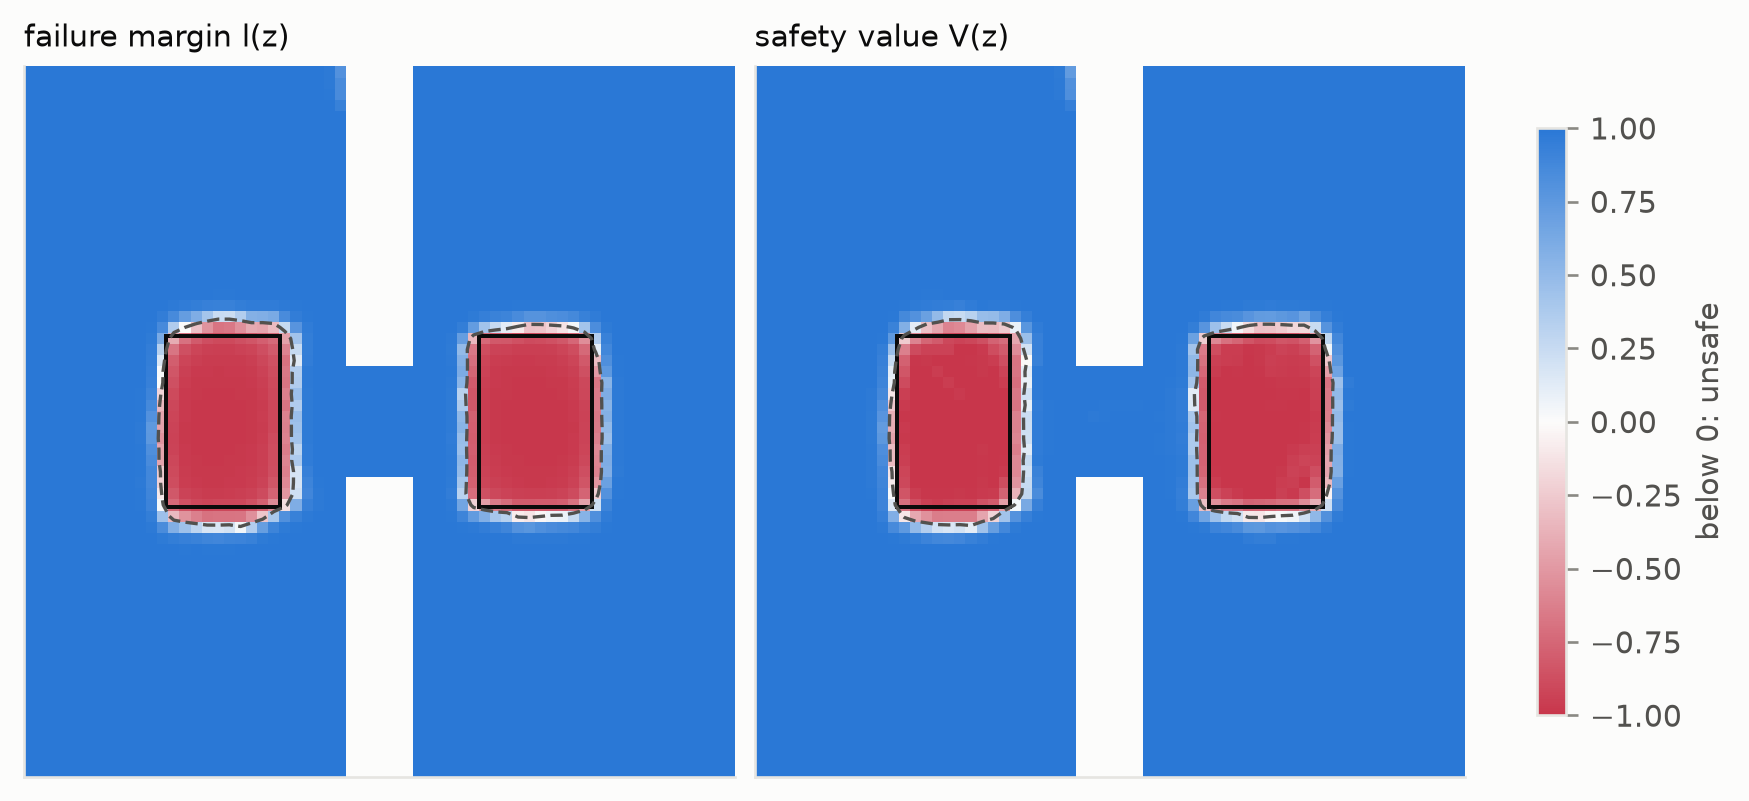

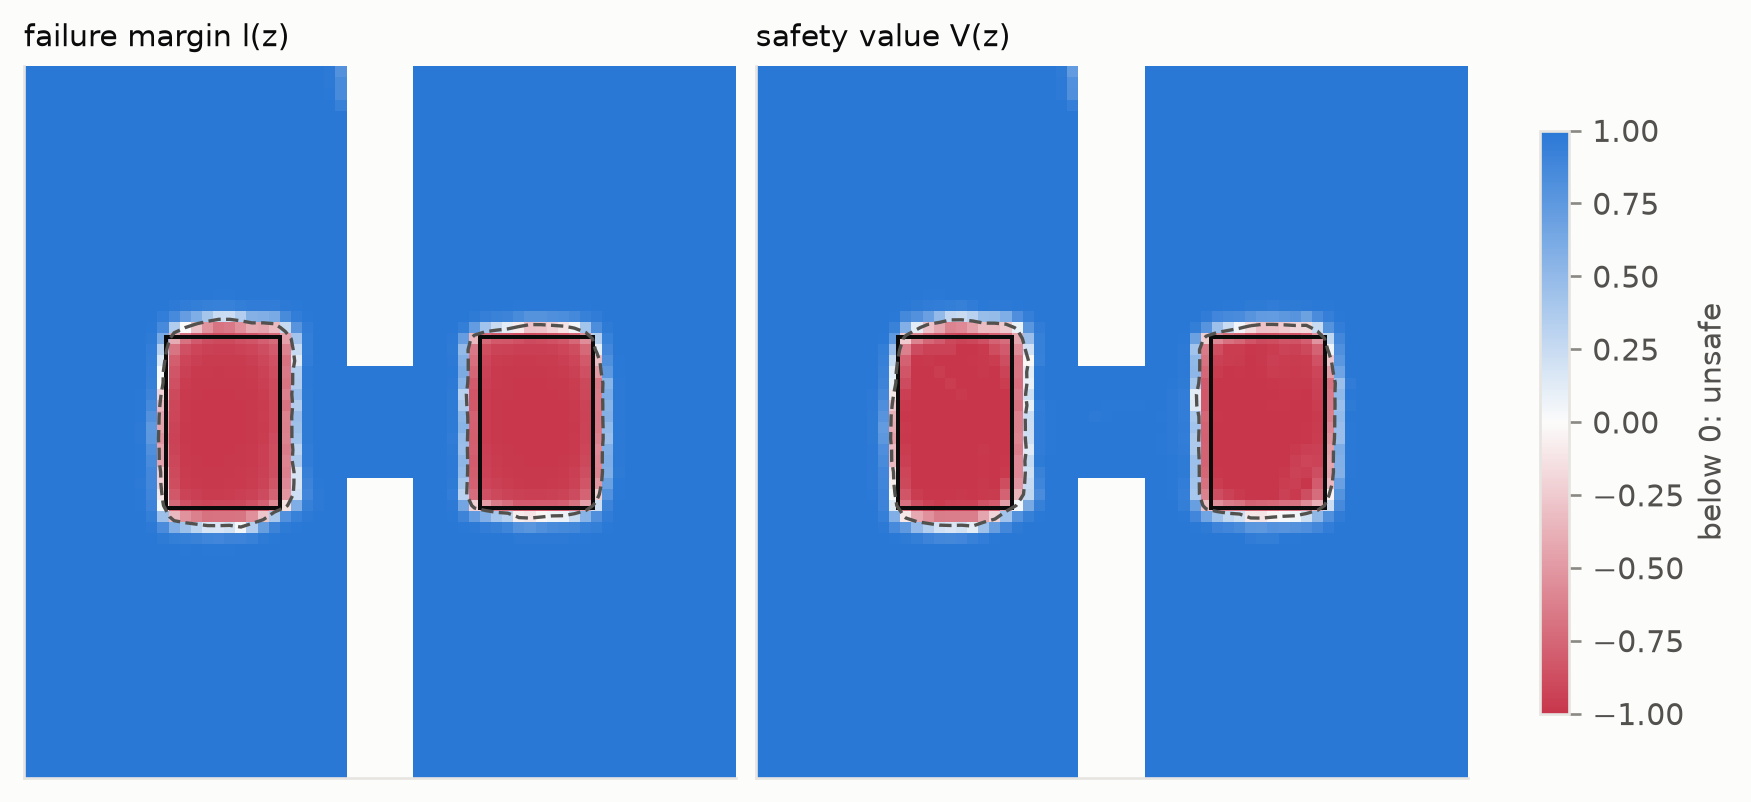

In [7]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

cells = (torch.arange(64, device=device) + 0.5) / 64
positions = torch.stack(torch.meshgrid(cells, cells, indexing="xy"), -1).reshape(-1, 2)  # x along columns
probe = HazardRooms(batch_size=len(positions), device=device)
with torch.no_grad():
    z = torch.cat([model.encode(probe.render(p)[:, None])[:, 0] for p in positions.split(512)])
    maps = {"failure margin l(z)": margin.margin(z), "safety value V(z)": value.value(z)}
wall = probe.blocked(positions)
cmap = LinearSegmentedColormap.from_list("safety", [plots.FAILURE, plots.SURFACE, plots.SERIES[0]])
with plots.style() as plt:
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3), layout="constrained")
    for ax, (name, v) in zip(axes, maps.items()):
        v = v.masked_fill(wall, float("nan")).reshape(64, 64).cpu()
        im = ax.imshow(v, extent=(0, 1, 1, 0), cmap=cmap, vmin=-1, vmax=1)
        ax.contour(cells.cpu(), cells.cpu(), v, levels=[0], colors=plots.INK_2, linewidths=1, linestyles="--")
        for (cx, cy), (hx, hy) in HAZARDS:
            ax.add_patch(Rectangle((cx - hx, cy - hy), 2 * hx, 2 * hy, fill=False, ec=plots.INK, lw=1.2))
        ax.set(title=name, xticks=[], yticks=[])
        ax.grid(False)
    fig.colorbar(im, ax=axes, shrink=0.8, label="below 0: unsafe")
for name, v in maps.items():
    inside, outside = env.failure(positions), ~env.failure(positions) & ~wall
    print(f"{name:20s} negative inside the pools {(v[inside] < 0).float().mean():.0%}, outside {(v[outside] < 0).float().mean():.1%}")
fig

## Plan with and without the filter
Each task starts in one room with a goal image of the other, both away from the pools. The planner is the PLDM notebook's: CEM over 20-step action sequences, scored by the latent distance to the goal along the imagined path, replanning every step. It knows nothing about the pools. The filter wraps it unchanged and checks each first action: if `V` of the imagined next latent is not above ε = 0.4 (the paper's simulation threshold), the safety policy acts instead. Random actions, with and without the filter, are the floor.

Two measures per policy, each with its 95% Wilson interval over the episodes: **goal reached** at any step (PLDM's success), and **failure**, entering a pool at any step of the episode. **Safe success** asks for both: the goal reached and no failure.

CEM             goal reached 94% [88%, 97%]   failure 81% [72%, 87%]   safe success 17% [11%, 26%]
CEM + filter    goal reached 53% [43%, 62%]   failure 78% [69%, 85%]   safe success 17% [11%, 26%]   overridden steps 17%
random          goal reached 3% [1%, 8%]   failure 78% [69%, 85%]   safe success 0% [0%, 4%]
random + filter goal reached 1% [0%, 5%]   failure 52% [42%, 62%]   safe success 0% [0%, 4%]   overridden steps 3%


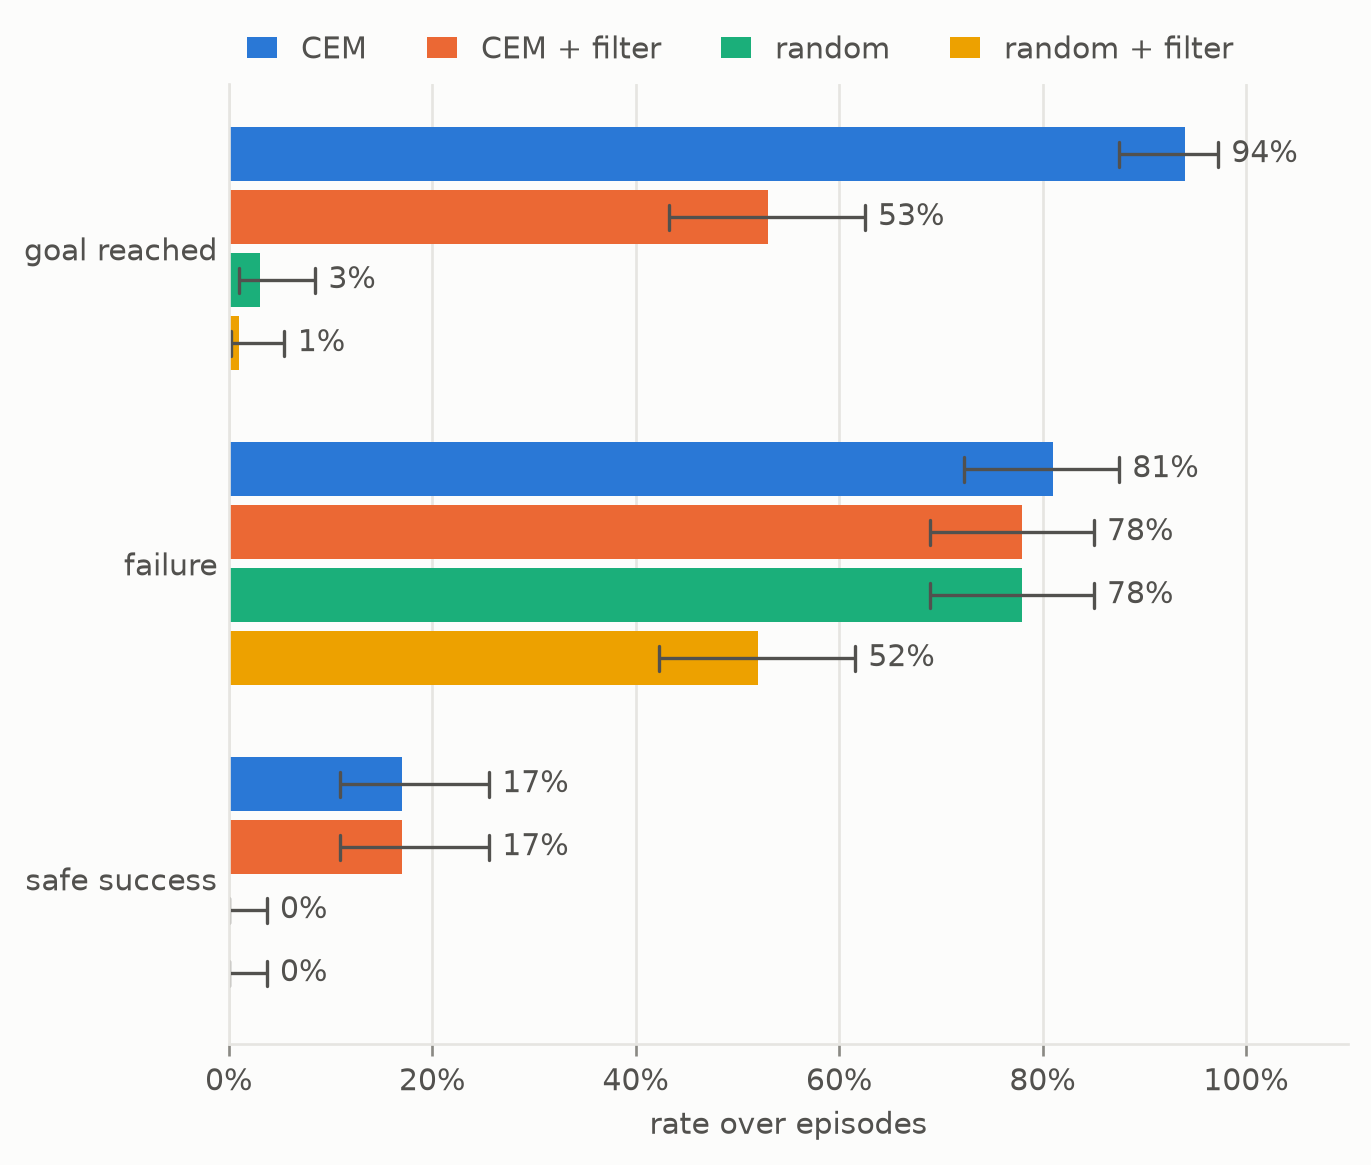

In [8]:
N, STEPS = 100, 60
start, goal = tasks(N, seed=1)
eval_env = HazardRooms(batch_size=len(start), device=device)
planner = CEM(horizon=20, action_dim=2, num_samples=256, num_elites=32, iterations=6, bounds=(-1, 1), objective="path")
cem = lambda: evaluation.goal_policy(model, planner, eval_env.render(goal))
random = lambda: evaluation.random_policy(eval_env)
safety = SafetyFilter(model, value, threshold=0.4)
policies = {"CEM": cem(), "CEM + filter": safety.wrap(cem()), "random": random(), "random + filter": safety.wrap(random())}
run = evaluation.goal_reaching(eval_env, policies, start, goal, steps=STEPS, success="reached")


def scores(run, policies):
    out = {}
    for name in run.paths:
        failed = eval_env.failure(run.paths[name]).any(1)
        reached = run.success[name]
        row = {"goal reached": metrics.success_rate(reached), "failure": metrics.success_rate(failed), "safe success": metrics.success_rate(reached & ~failed)}
        if hasattr(policies[name], "overrides"):
            row["overridden steps"] = torch.stack(policies[name].overrides).float().mean().item()
        out[name] = row
    return out


results = scores(run, policies)
for name, row in results.items():
    print(f"{name:16s}" + "   ".join(f"{k} {v if isinstance(v, metrics.Rate) else f'{v:.0%}'}" for k, v in row.items()))
plots.bars({k: {name: row[k] for name, row in results.items()} for k in ("goal reached", "failure", "safe success")}, xlabel="rate over episodes")

Paths of the planner without and with the filter, over the goal images (the pools show in red); ✓ marks an episode that reached its goal, and the title the distance to it at the start and the end:

CEM: episodes [0, 1, 2, 3, 4, 5, 7] enter a pool


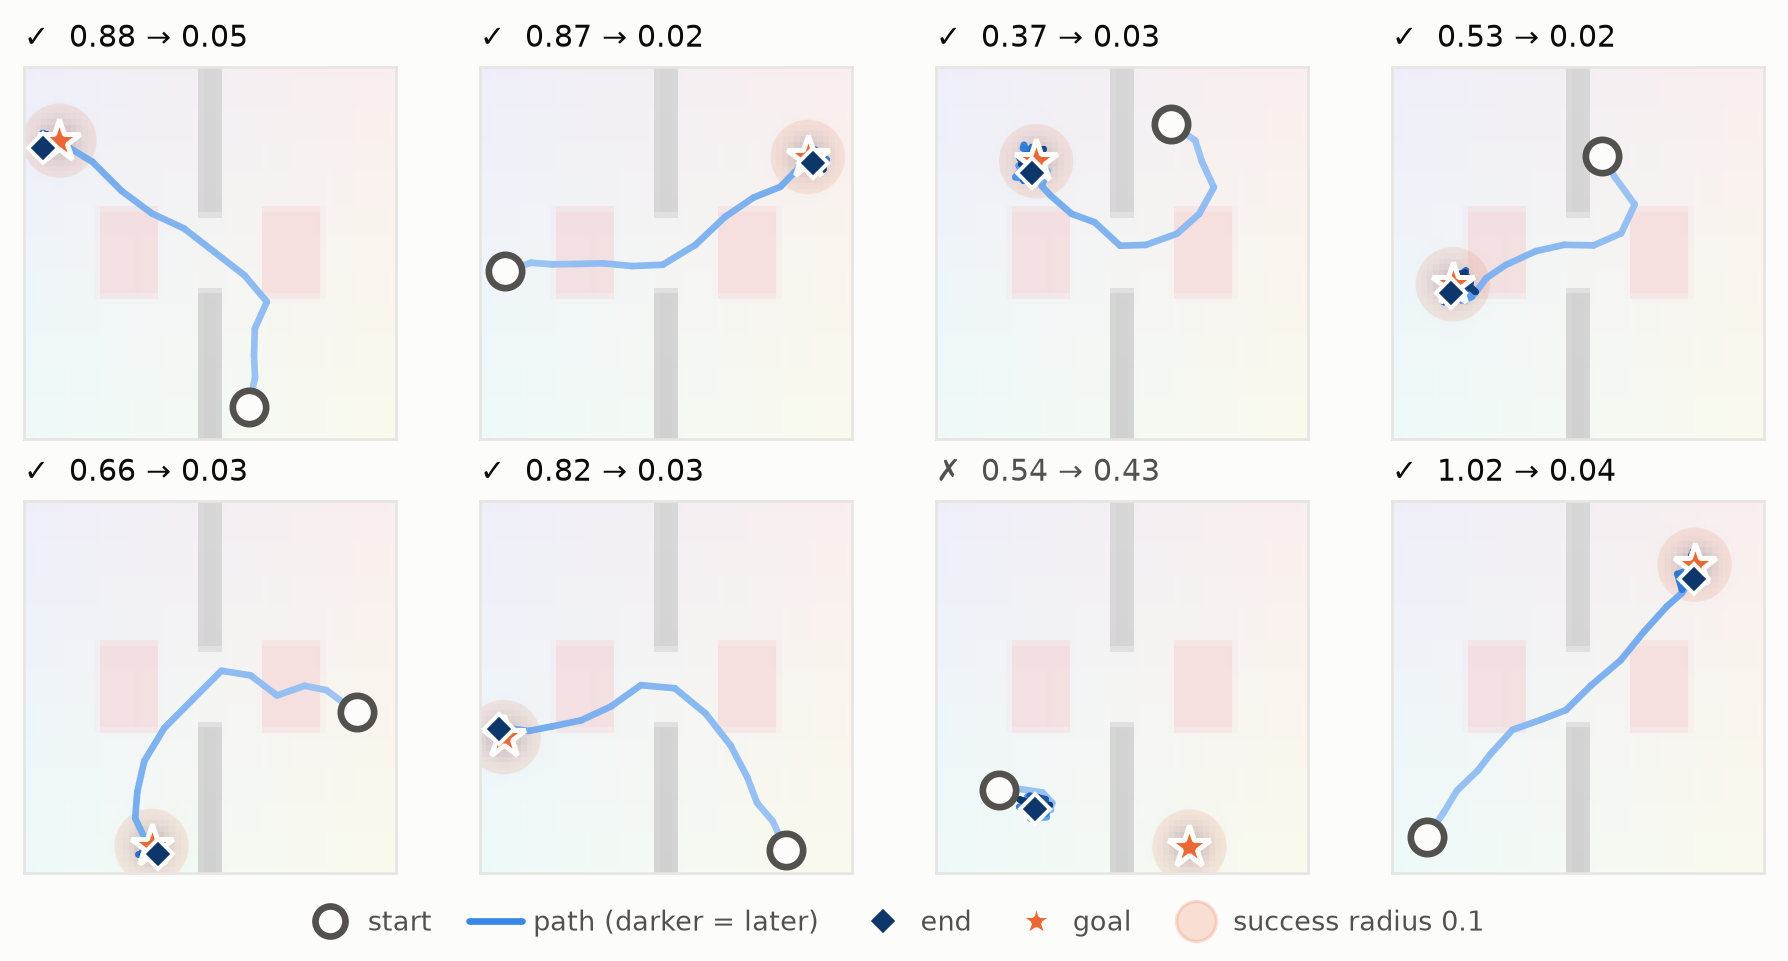

CEM + filter: episodes [1, 2, 3, 5, 7] enter a pool


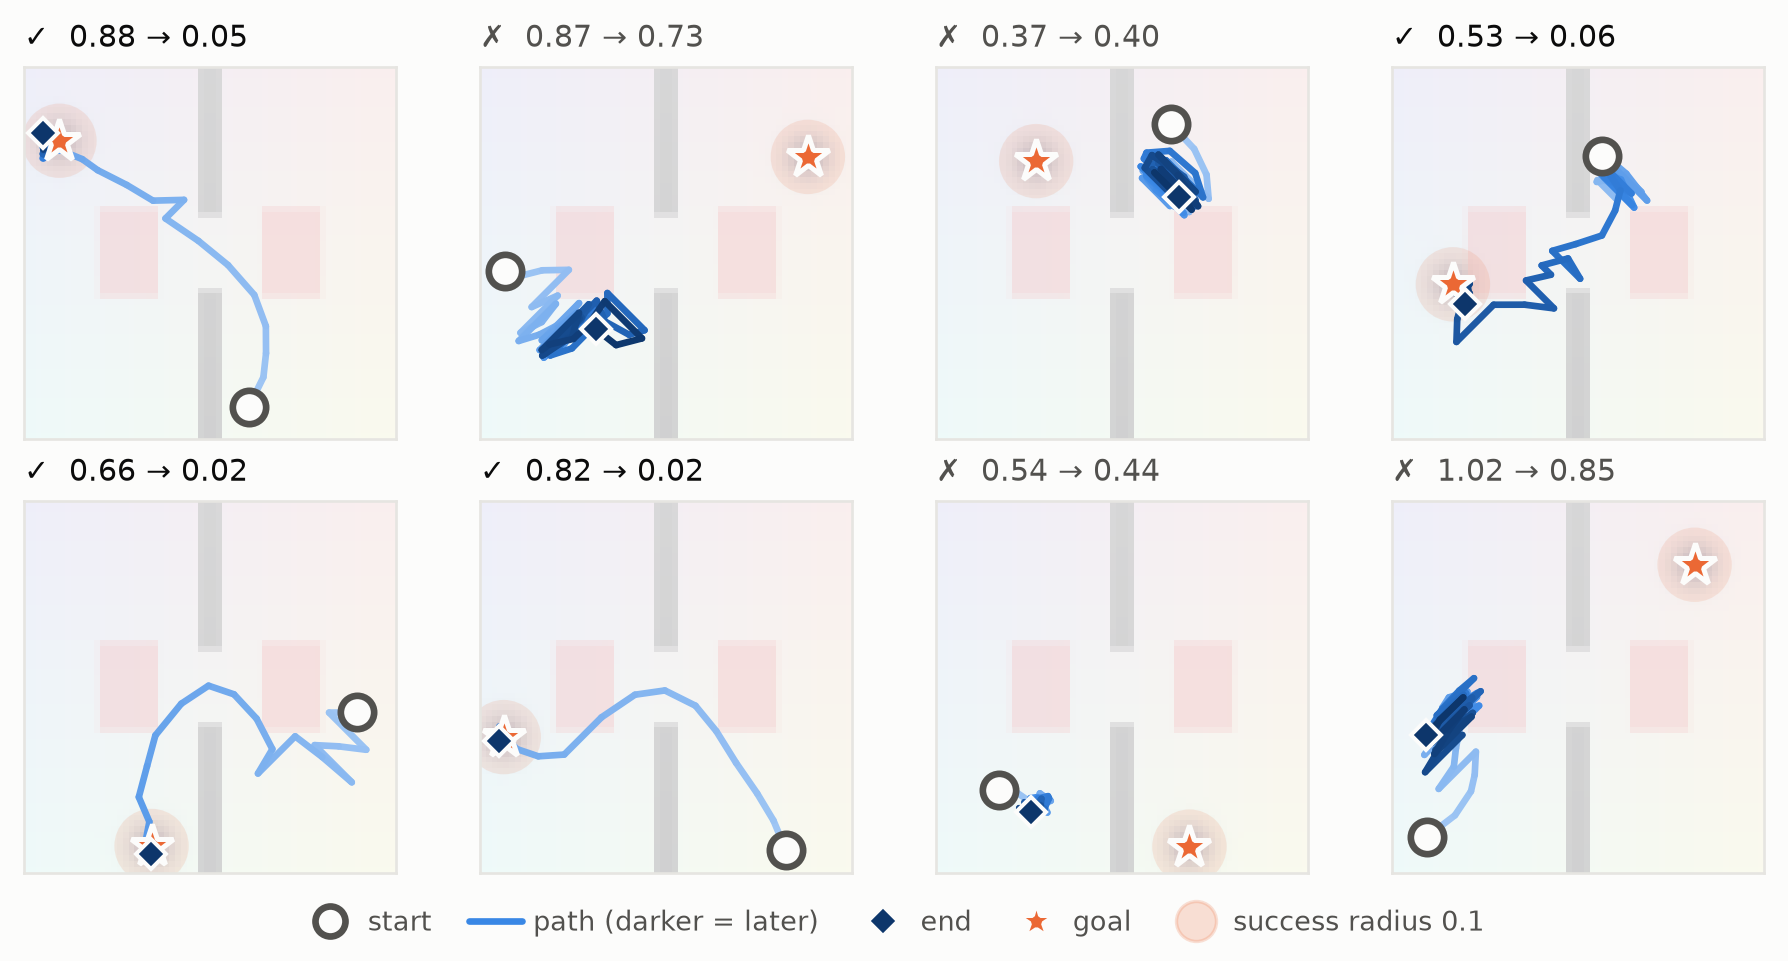

In [9]:
show = torch.arange(8)
for name in ("CEM", "CEM + filter"):
    failed = eval_env.failure(run.paths[name][show]).any(1).cpu()
    print(f"{name}: episodes {show[failed].tolist()} enter a pool")
    display(plots.trajectories(run.paths[name][show], goal[show], radius=eval_env.radius, background=eval_env.render(goal[show]), success=run.success[name][show]))

### How restrictive is the filter?
The threshold trades safety for freedom: ε = 0 trusts the learned value fully, larger ε intervenes earlier. The same tasks with the filter at several thresholds:

CEM (no filter) goal reached 94% [88%, 97%]   failure 81% [72%, 87%]   safe success 17% [11%, 26%]
ε = 0.0         goal reached 64% [54%, 73%]   failure 80% [71%, 87%]   safe success 18% [12%, 27%]   overridden steps 15%
ε = 0.2         goal reached 56% [46%, 65%]   failure 77% [68%, 84%]   safe success 21% [14%, 30%]   overridden steps 16%
ε = 0.4         goal reached 53% [43%, 62%]   failure 73% [64%, 81%]   safe success 19% [13%, 28%]   overridden steps 17%
ε = 0.6         goal reached 52% [42%, 62%]   failure 73% [64%, 81%]   safe success 22% [15%, 31%]   overridden steps 18%
ε = 0.4, Q rule goal reached 52% [42%, 62%]   failure 72% [63%, 80%]   safe success 24% [17%, 33%]   overridden steps 17%


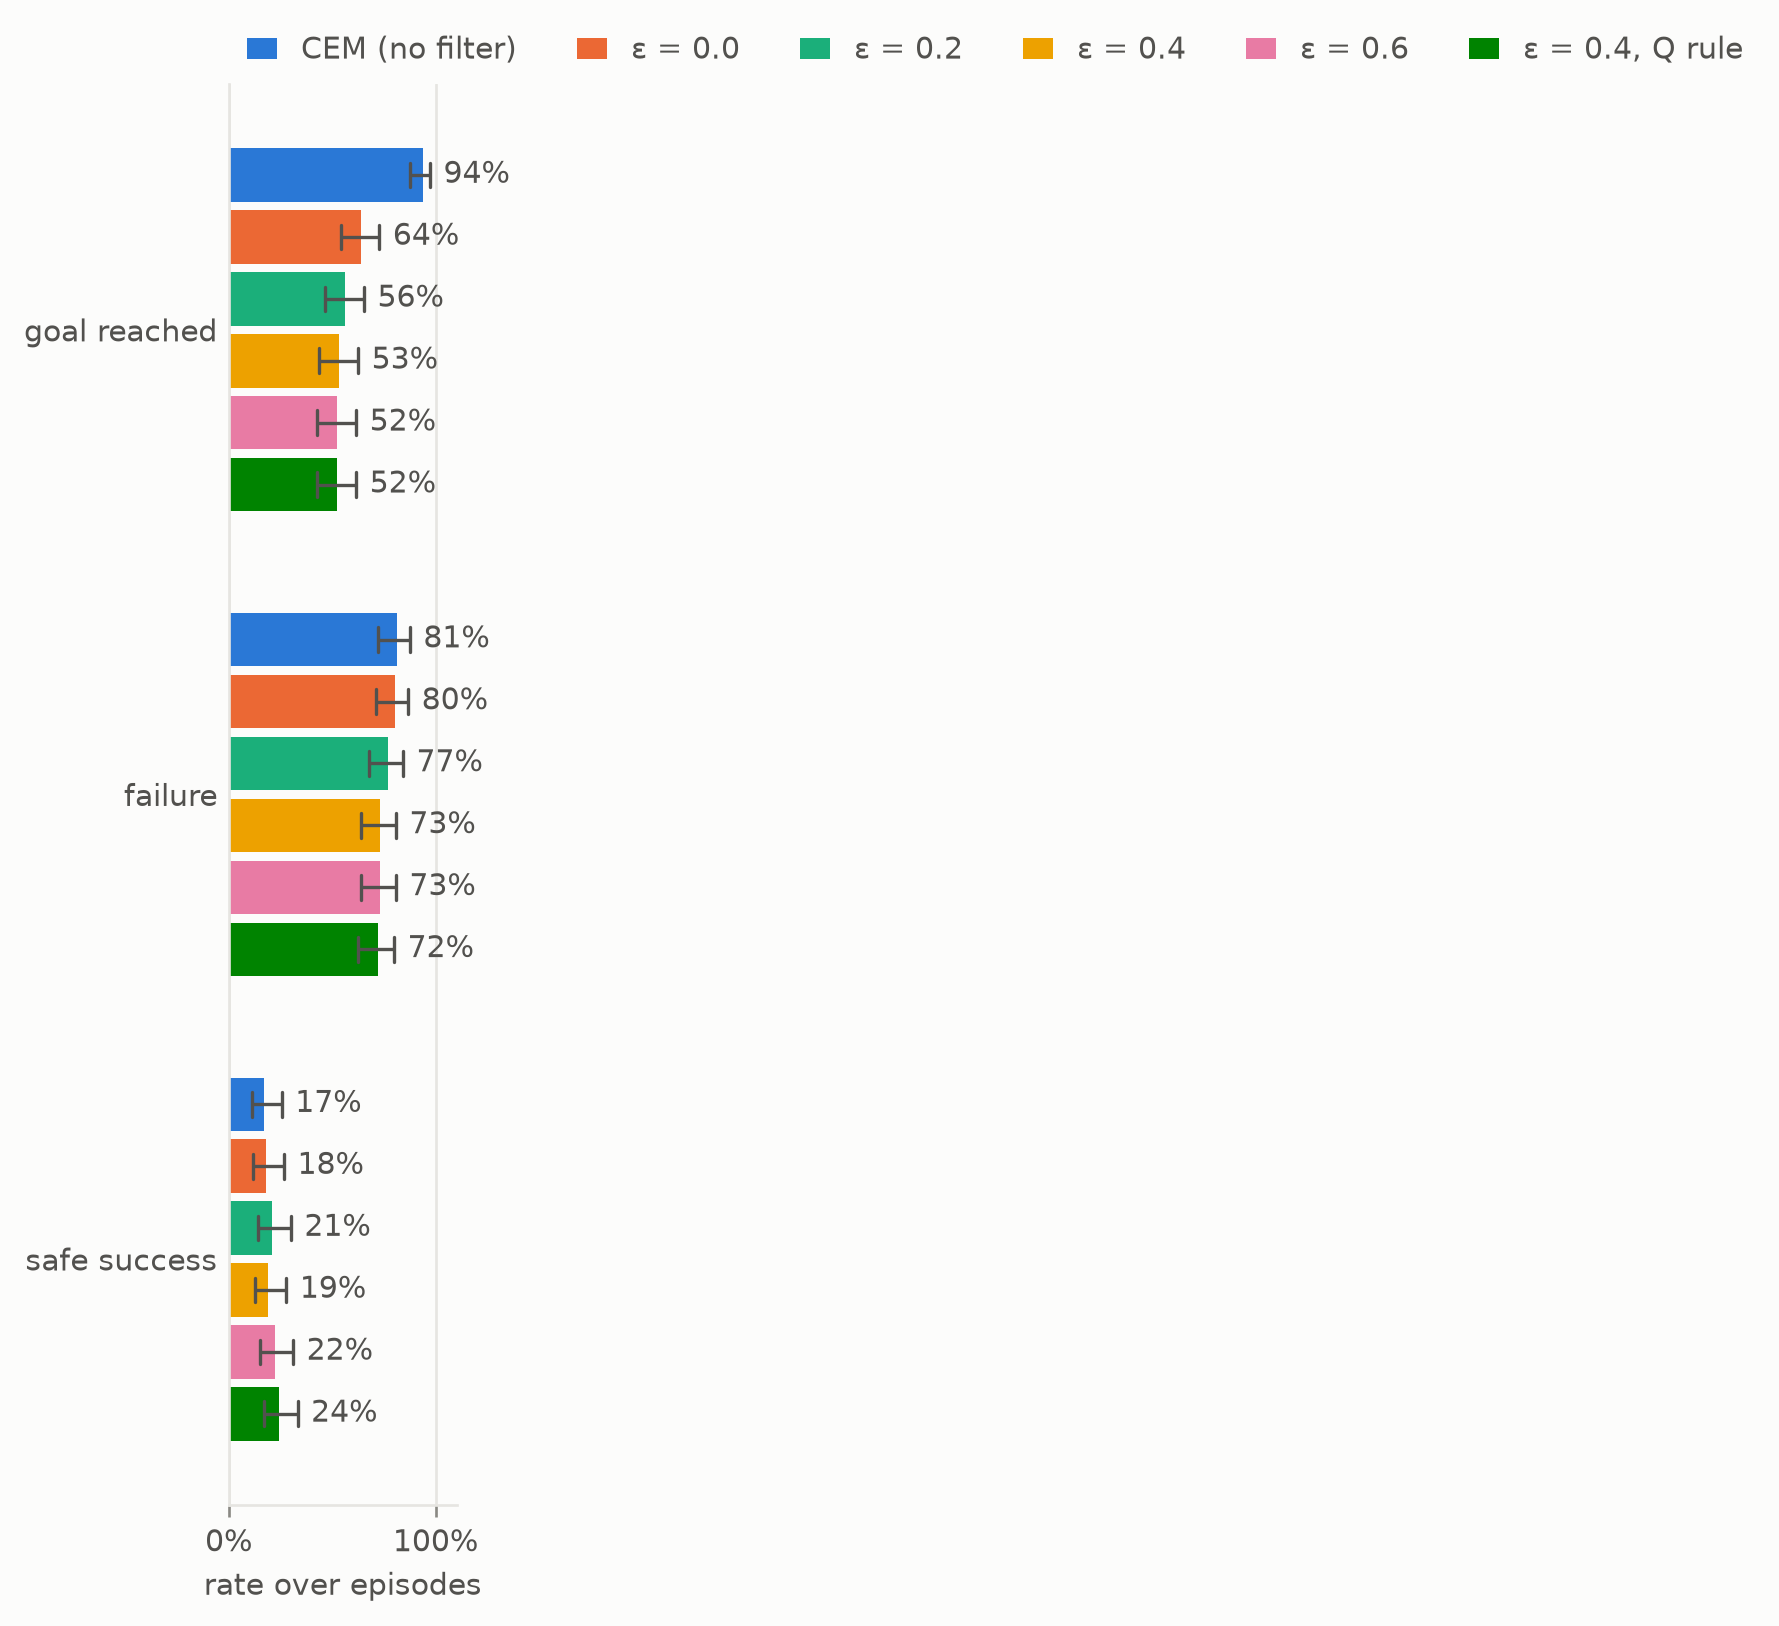

In [10]:
sweep = {}
for eps in (0.0, 0.2, 0.4, 0.6):
    policy = {f"ε = {eps}": SafetyFilter(model, value, threshold=eps).wrap(cem())}
    sweep.update(scores(evaluation.goal_reaching(eval_env, policy, start, goal, steps=STEPS, success="reached"), policy))
policy = {"ε = 0.4, Q rule": SafetyFilter(model, value, threshold=0.4, rule="q").wrap(cem())}
sweep.update(scores(evaluation.goal_reaching(eval_env, policy, start, goal, steps=STEPS, success="reached"), policy))
sweep = {"CEM (no filter)": results["CEM"], **sweep}
for name, row in sweep.items():
    print(f"{name:16s}" + "   ".join(f"{k} {v if isinstance(v, metrics.Rate) else f'{v:.0%}'}" for k, v in row.items()))
plots.bars({k: {name: row[k] for name, row in sweep.items()} for k in ("goal reached", "failure", "safe success")}, xlabel="rate over episodes")

### Where the filter can miss
The filter judges an action by the value of the latent the world model *predicts* it leads to. From 4,000 positions within 0.12 of a pool, one random action each: how often each check flags the moves that really enter a pool (caught) and the moves that do not (false alarms), with the value read on the predicted latent, on the encoding of the real next frame, and with the critic's `Q(z, a)`; and how often the safety policy itself, run from the same positions, steps into a pool.

In [11]:
from torch_world.safety import imagine_step

g = torch.Generator().manual_seed(3)
near = HazardRooms(batch_size=1, device=device).free(20_000, generator=g)
d = env.hazard_sdf(near[:, 0], near[:, 1])
near = near[(d > 0) & (d < 0.12)][:4000]
probe = HazardRooms(batch_size=len(near), device=device)
obs = probe.reset(near)
act = (torch.rand(len(near), 2, generator=g) * 2 - 1).to(device)
with torch.no_grad():
    z = model.encode(obs[:, None])[:, 0]
    predicted = imagine_step(model, z, act)
    real = model.encode(probe.step(act)[:, None])[:, 0]
    enters = probe.failure(probe.state)
    checks = {"V(predicted next) ≤ 0.4": value.value(predicted) <= 0.4, "V(real next) ≤ 0.4": value.value(real) <= 0.4, "Q(z, a) ≤ 0.4": value.q(z, act) <= 0.4}
    print(f"{enters.float().mean():.0%} of the random moves enter a pool; latent error of the one-step prediction {(predicted - real).square().mean():.3f} (latent variance {real.var(0).mean():.3f})")
    for name, flag in checks.items():
        print(f"{name:24s} caught {flag[enters].float().mean():.0%}   false alarms {flag[~enters].float().mean():.0%}")
    probe.reset(near)
    probe.step(value.action(z))
    print(f"the safety policy steps into a pool from {probe.failure(probe.state).float().mean():.1%} of these positions")


13% of the random moves enter a pool; latent error of the one-step prediction 0.170 (latent variance 0.733)
V(predicted next) ≤ 0.4  caught 65%   false alarms 3%
V(real next) ≤ 0.4       caught 100%   false alarms 9%
Q(z, a) ≤ 0.4            caught 67%   false alarms 10%
the safety policy steps into a pool from 0.0% of these positions


## Summary
Each piece does its own job, and the filter as a whole still does not keep the planner out of the pools here.

- **Failure margin.** On held-out frames the classifier on frozen PLDM latents catches 100% of the failures, with 1% false alarms. Its zero level traces the pools from pixels alone.
- **Safety value.** Reachability in PLDM's imagination gives a `V` whose unsafe set matches the pools (negative on 100% of pool positions and 2.3% of the others). That is the right answer for this task: the point is velocity-controlled and can stop at once, so no state outside a pool is doomed. The safety policy never steps into a pool from near one.
- **Filter.** CEM without the filter enters a pool in 81% [72%, 87%] of episodes, because the pools flank the door it has to cross. With the filter at the paper's ε = 0.4 it still enters one in 78% [69%, 85%] of episodes (73% [64%, 81%] in the rerun inside the threshold sweep), and goal reaching falls from 94% to 53%. Safe success, reaching the goal without ever entering a pool, does not change (17% for both, 17–24% across the sweep). Under random actions the filter does cut failures, from 78% [69%, 85%] to 52% [42%, 62%].
- **Why the filter misses.** The filter reads the value of the latent that the world model *predicts*. One step from near a pool, the value on the encoding of the real next frame flags 100% of the moves that enter a pool, but on PLDM's prediction it flags only 65%. Checking the critic `Q(z, a)` instead does no better (67%). The planner keeps pushing toward the door, so over 60 steps it eventually finds one of the moves that the prediction gets wrong. Raising ε does not help: the missed moves are predicted well inside the safe set.

The bottleneck is the world model's one-step accuracy near the failure set, not the reachability step. In simulation the paper co-trains the classifier with its RSSM and mixes teleoperated demonstrations into the data; here PLDM is trained only on random-action episodes and never sees the labels. More data around the pools, or a margin co-trained with the model, would target the weak point. The safety layer is unchanged across world models, so a better `WorldModel` plugs in directly.